## Set Library Path

In [1]:
.libPaths("/home/vhaghani/anaconda3/envs/jupyter_nb_R4.4.2/lib/R/library")

## Load Libraries

In [3]:
library(tidyr)
library(dplyr)
library(ggplot2)

# Load Metadata

In [15]:
# Read in metadata
metadata <- read.csv("metadata.csv")

# Split metadata by gene to create named lists
metadata <- split(metadata, metadata$Gene)

# Remove any empty data frames that might result from filtering
metadata <- metadata[sapply(metadata, nrow) > 0]

# View
str(metadata)

List of 1
 $ MECP2:'data.frame':	32 obs. of  23 variables:
  ..$ Gene                      : chr [1:32] "MECP2" "MECP2" "MECP2" "MECP2" ...
  ..$ Sample_ID                 : chr [1:32] "KB1" "KB2" "KB3" "KB19" ...
  ..$ Sample_Name               : chr [1:32] "CO_R270X_B1_d18_A1" "CO_R270X_B1_d18_A2" "CO_R270X_B1_d18_A3" "CO_R270X_B2_d18_A1" ...
  ..$ Cell_Type                 : chr [1:32] "Cerebral_Organoid" "Cerebral_Organoid" "Cerebral_Organoid" "Cerebral_Organoid" ...
  ..$ Genotype                  : chr [1:32] "MUT" "MUT" "MUT" "MUT" ...
  ..$ Time_Point                : chr [1:32] "D18" "D18" "D18" "D18" ...
  ..$ Group                     : chr [1:32] "R270X_D18" "R270X_D18" "R270X_D18" "R270X_D18" ...
  ..$ Replicate                 : int [1:32] 1 2 3 4 5 6 1 2 3 4 ...
  ..$ Clean_Sample_Name         : chr [1:32] "R270X_D18_1" "R270X_D18_2" "R270X_D18_3" "R270X_D18_4" ...
  ..$ Batch                     : int [1:32] 0 0 0 1 1 1 0 0 0 1 ...
  ..$ D18_MUT_vs_D18_WT         : int 

In [16]:
# View groups 
for (gene_name in names(metadata)) {
  cat("\n=== Group counts for", gene_name, "===\n")
  print(table(metadata[[gene_name]]$Group))
}


=== Group counts for MECP2 ===

R270X_D18 R270X_D46 R270X_D90    WT_D18    WT_D46    WT_D90 
        6         4         6         6         5         5 


# Load Counts

In [18]:
# Read in counts
counts <- read.delim("05_gene_counts/MECP2_normalized_counts.txt")

# Read in metadata and select only the mapping columns to rename samples
mapping_df <- read.csv("metadata.csv")[, c("Sample_Name", "Clean_Sample_Name")]

# Create mapping
name_mapping <- setNames(mapping_df$Clean_Sample_Name, mapping_df$Sample_Name)

# Remove whitespace
colnames(counts) <- trimws(colnames(counts))

# Rename columns
colnames(counts) <- name_mapping[colnames(counts)]

# Drop columns that don't map
counts <- counts[, !is.na(colnames(counts))]

# View
head(counts)

,R270X_D18_1,R270X_D18_2,R270X_D18_3,R270X_D18_4,R270X_D18_5,R270X_D18_6,R270X_D46_1,R270X_D46_2,R270X_D46_3,R270X_D46_4,⋯,WT_D46_1,WT_D46_2,WT_D46_3,WT_D46_4,WT_D46_5,WT_D90_1,WT_D90_2,WT_D90_3,WT_D90_4,WT_D90_5
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A0A024R0Q4,1.5955131,1.776155,1.051596,1.325690,1.876562,1.2972164,1.441147,1.793023,1.9981165,1.997648,⋯,2.0175780,2.258242,1.785696,1.764698,0.45101005,1.779600,2.520144,1.991368,2.835845,1.990374
A0A024R5G2,6.5338210,6.600780,6.693552,6.926624,6.770172,7.3023333,6.433098,6.170686,6.3606658,6.624274,⋯,6.2838073,6.174269,6.288047,6.365530,7.34696247,5.865562,5.584527,6.156353,5.753729,5.910733
A0A024RAA5,1.0213060,1.776155,1.051596,2.429266,2.176069,0.6618769,2.887948,2.543490,3.4020222,2.988700,⋯,3.3312998,3.147539,3.043483,2.958170,2.22289674,2.911341,3.428417,2.981747,2.097798,1.990374
A0A024RAJ1,0.4523278,1.148576,1.271631,2.222271,1.263736,2.7728478,1.441147,0.917640,1.7066873,1.232729,⋯,0.7735121,1.685210,1.922383,0.060944,-0.50075523,2.622903,2.520144,1.867580,1.095090,1.009635
A0A024RBW1,4.0801219,4.367480,4.006765,4.252824,3.325689,2.9467234,1.032681,1.618853,0.8502006,1.873739,⋯,1.0311523,1.537162,1.274966,2.524291,0.05223064,2.361044,1.252954,1.732164,2.097798,1.415074
A0A024RDL5,3.2182169,2.878073,3.360271,3.382059,3.699480,3.8790375,4.401071,4.862035,4.1892690,4.305232,⋯,4.0945736,4.635590,4.011270,3.955019,4.61330215,3.095188,3.184200,2.920766,4.129587,4.880361


# Make PCA

In [19]:
# Transpose counts so samples are rows and genes are columns
pca_data <- as.data.frame(t(counts))

In [21]:
# Create sample metadata from row names
metadata <- data.frame(
  sample = rownames(pca_data)
) %>%
  mutate(
    mut_status = gsub("_.*", "", sample),  
    timepoint = gsub(".*_(D\\d+)_.*", "\\1", sample), 
    timepoint = factor(timepoint, levels = c("D18", "D46", "D90")) 
  )

# View
head(metadata)

,sample,mut_status,timepoint
,<chr>,<chr>,<fct>
1,R270X_D18_1,R270X,D18
2,R270X_D18_2,R270X,D18
3,R270X_D18_3,R270X,D18
4,R270X_D18_4,R270X,D18
5,R270X_D18_5,R270X,D18
6,R270X_D18_6,R270X,D18


In [22]:
# Perform PCA
pca_matrix <- pca_data[, apply(pca_data, 2, function(x) !any(is.na(x)) & sd(x) > 0)]
pca_result <- prcomp(pca_matrix, scale. = TRUE, center = TRUE)

In [23]:
# Calculate variance explained
variance_explained <- (pca_result$sdev^2 / sum(pca_result$sdev^2)) * 100

In [24]:
# Create data frame for plotting
pca_plot_data <- data.frame(
  sample = rownames(pca_result$x),
  PC1 = pca_result$x[, 1],
  PC2 = pca_result$x[, 2]
) %>%
  left_join(metadata, by = "sample")

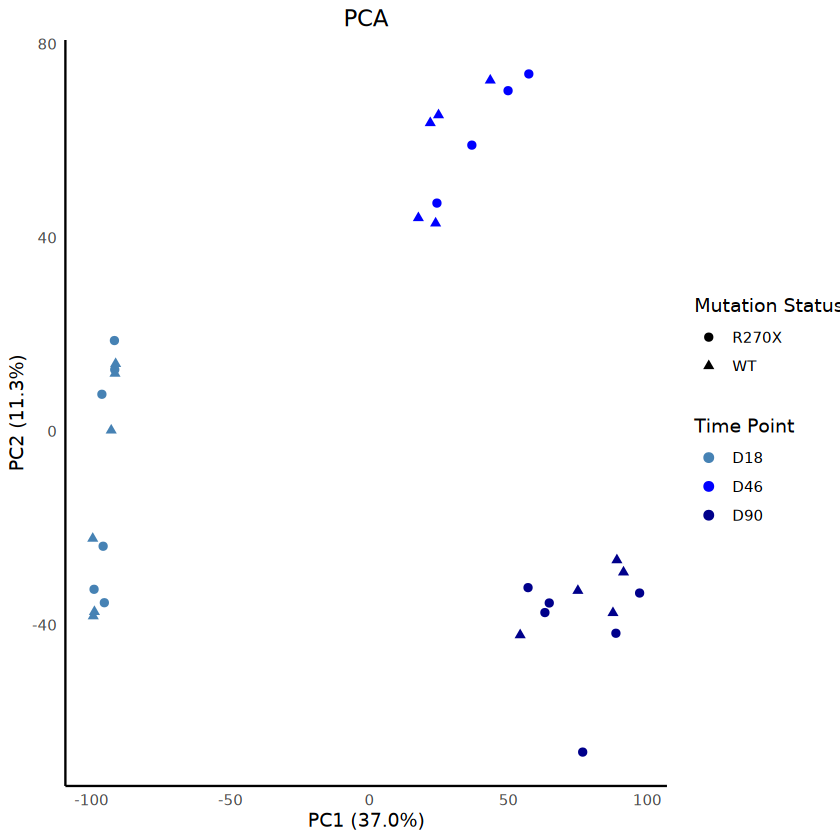

In [40]:
# Create PCA plot
pca_plot <- ggplot(pca_plot_data, aes(x = PC1, y = PC2, 
                                      color = timepoint, 
                                      shape = mut_status)) +
  geom_point(size = 2) +
  labs(
    title = "PCA",
    x = sprintf("PC1 (%.1f%%)", variance_explained[1]),
    y = sprintf("PC2 (%.1f%%)", variance_explained[2]),
    color = "Time Point",
    shape = "Mutation Status"
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(hjust = 0.5),
    legend.position = "right",
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank(),
    axis.line = element_line(color = "black"),
  ) +
  scale_color_manual(values = c("D18" = "steelblue", "D46" = "blue", "D90" = "darkblue")) +
  scale_shape_manual(values = c("R270X" = 16, "WT" = 17))

# Display plot
print(pca_plot)

In [41]:
# Save plot
ggsave("PCA_plot.pdf",
  plot = pca_plot,
  device = "pdf",
  path = "07_DEG_Figures",
  scale = 1,
  width = 4.5,
  height = 4,
  units = "in",
  dpi = 600,
  create.dir = TRUE,
)